# 项目：用逻辑回归预测泰坦尼克号幸存情况

## 分析目标

此数据分析报告的目的是，基于泰坦尼克号乘客的性别和船舱等级等属性，对幸存情况进行逻辑回归分析，从而能利用得到的模型，对未知幸存情况的乘客，根据属性预测是否从沉船事件中幸存。

## 简介

> 泰坦尼克号（英语：RMS Titanic）是一艘奥林匹克级邮轮，于1912年4月首航时撞上冰山后沉没。泰坦尼克号是同级的3艘超级邮轮中的第2艘，与姐妹船奥林匹克号和不列颠号为白星航运公司的乘客们提供大西洋旅行。

> 泰坦尼克号由位于北爱尔兰贝尔法斯特的哈兰·沃尔夫船厂兴建，是当时最大的客运轮船，由于其规模相当一艘现代航空母舰，因而号称“上帝也沉没不了的巨型邮轮”。在泰坦尼克号的首航中，从英国南安普敦出发，途经法国瑟堡-奥克特维尔以及爱尔兰昆士敦，计划横渡大西洋前往美国纽约市。但因为人为错误，于1912年4月14日船上时间夜里11点40分撞上冰山；2小时40分钟后，即4月15日凌晨02点20分，船裂成两半后沉入大西洋，死亡人数超越1500人，堪称20世纪最大的海难事件，同时也是最广为人知的海难之一。

数据集包括两个数据表：`titianic_train.csv`和`titanic_test.csv`。

`titianic_train.csv`记录了超过八百位泰坦尼克号乘客在沉船事件后的幸存情况，以及乘客的相关信息，包括所在船舱等级、性别、年龄、同乘伴侣/同胞数量、同乘父母/孩子数量，等等。

`titanic_test.csv`只包含乘客（这些乘客不在`titianic_train.csv`里）相关信息，此文件可以被用于预测乘客是否幸存。

`titianic_train.csv`每列的含义如下：
- PassengerId：乘客ID
- survival：是否幸存
   - 0	否
   - 1	是
- pclass：船舱等级
   - 1	一等舱
   - 2	二等舱
   - 3  三等舱
- sex：性别
- Age：年龄
- sibsp：同乘伴侣/同胞数量
- parch：同乘父母/孩子数量
- ticket：船票号
- fare：票价金额
- cabin：船舱号
- embarked：登船港口
   - C  瑟堡
   - Q  皇后镇
   - S  南安普敦
   
   
`titianic_test.csv`每列的含义和上面相同，但不具备survival变量的数据，即是否幸存。

In [413]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

In [414]:
#现在还未构建模型，因此只需要引入train数据集并将其进行评估清理等，然后用于训练模型即可。
tr=pd.read_csv(r"C:\Users\30338\Desktop\数据处理学习\5数据分析\titanic_train.csv")
tt=pd.read_csv(r"C:\Users\30338\Desktop\数据处理学习\5数据分析\titanic_test.csv")
tr.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 数据评估和清洗  
第一步先对训练数据集进行结构上和内容上的评估清洗  
结构上整齐数据应该满足：“每个变量为一列，每个观察值为一行，每种类型的观察单位为一个表格”  
内容上包括：重复数据、不一致数据、无效或错误数据、数据类型是否需要转换等。

In [415]:
#对结构上进行评估，查看数据集的基本信息
tr.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [416]:
#经过对当前的数据观察可以发现数据基本满足结构要求，不对其进行结构性处理，接下来就是对其进行数据内容上的评估清洗
tr.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [417]:
#经过观察可以发现，Age、Cabin、Embarked这三列存在缺失值，将在此后进行处理。
#数据类型方面，`PassengerId`表示乘客ID，数据类型不应为数字，应为字符串，所以需要进行数据格式转换。
#已知`Survived`（是否幸存）、`Pclass`（船舱等级）、`Sex`（性别）、`Embarked`（登船港口）都是分类数据，可以把数据类型都转换为Category。
tr['PassengerId'] = tr['PassengerId'].astype(str)
tr['Survived'] = tr['Survived'].astype('category')
tr['Pclass'] = tr['Pclass'].astype('category')
tr['Sex'] = tr['Sex'].astype('category')
tr['Embarked'] = tr['Embarked'].astype('category')
ctr=tr.copy()
ctr.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    str     
 1   Survived     891 non-null    category
 2   Pclass       891 non-null    category
 3   Name         891 non-null    str     
 4   Sex          891 non-null    category
 5   Age          714 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    str     
 9   Fare         891 non-null    float64 
 10  Cabin        204 non-null    str     
 11  Embarked     889 non-null    category
dtypes: category(4), float64(2), int64(2), str(4)
memory usage: 59.4 KB


#### 处理缺失数据  
从上面`info`方法的输出结果来看，在`ctr`中，`Age`、`Cabin`和`Embarked`变量存在缺失值。

In [418]:
ctr[ctr['Age'].isna()]
#经过观察发现，虽然Age列存在缺失值，但是其缺失值的数量并不多，而且其他列数据仍旧具有价值，而回归分析则需要完整的数据不可以有缺失，因此可以使用中位数对Age列的缺失值进行填充。

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...,...
859,860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
868,869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S


In [419]:
ctr["Age"] = ctr['Age'].fillna(ctr['Age'].mean())
ctr[ctr['Age'].isna()]
#经过处理后，将Age列的缺失值填充为Age列的均值，查看Age列是否还存在缺失值，发现已经不存在缺失值了。
#开始对其他列Cabin和Embarked的缺失值进行处理.

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [420]:
ctr[ctr["Cabin"].isna()]
#由于船舱号对于数据分析没有关键影响作用，因此不将其纳入逻辑分析中，所以即使缺失，也不会影响分析结果，可以不对其进行处理。

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,29.699118,0,0,330877,8.4583,NaN,Q
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,349909,21.0750,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.000000,0,0,SOTON/OQ 392076,7.0500,NaN,S
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.000000,0,5,382652,29.1250,NaN,Q
886,887,0,2,"Montvila, Rev. Juozas",male,27.000000,0,0,211536,13.0000,NaN,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,29.699118,1,2,W./C. 6607,23.4500,NaN,S


In [421]:
ctr[ctr["Embarked"].isna()]
#Embarked缺失值的数量为2个,该变量没有对分析结果产生重大影响，可以不将其纳入分析，因此可以不对其进行处理。

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [422]:
#经过对数据的类型进行观察，发现PassengerID列的数据是唯一的，接下来查看其是否存在重复值
ctr[ctr.duplicated(subset=['PassengerId'])]
#经过对输出结果的观察可以发现，PassengerId列不存在重复值，因此不需要对其进行处理。

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


##### 接下来处理不一致数据  
不一致数据可能存在于所有分类变量中，因此要查看是否存在不同值实际指代同一目标的情况。

In [423]:
print(ctr["Survived"].value_counts())
print(ctr["Pclass"].value_counts())
print(ctr["Sex"].value_counts())
print(ctr["Embarked"].value_counts())
#从下面的输出结果来看，并不存在不一致数据，因此不进行不一致处理。

Survived
0    549
1    342
Name: count, dtype: int64
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Sex
male      577
female    314
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


##### 处理无效或不一致数据  
可以通过DataFrame的`describe`方法，对数值统计信息进行快速了解。

In [424]:
ctr.describe()
#从输出结果来看，猜测0元为增票的情况下，并不存在不符合现实意义的数据，因此不进行不合理数据处理。

,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208
std,13.002015,1.102743,0.806057,49.693429
min,0.420000,0.000000,0.000000,0.000000
25%,22.000000,0.000000,0.000000,7.910400
50%,29.699118,0.000000,0.000000,14.454200
75%,35.000000,1.000000,0.000000,31.000000
max,80.000000,8.000000,6.000000,512.329200


### 数据整理  
对数据的整理，与分析方向紧密相关。  
此次数据分析目标是根据泰坦尼克号乘客的相关信息，预测沉船事件发生后的生还概率。
数据变量包含乘客同乘伴侣/同胞数量，以及同乘父母/孩子数量，这些可帮助计算出船上家庭成员的数量。  
此时对同乘家庭成员数量是否会显著影响幸存感兴趣，因此可以创建一个新的变量，记录这一数值。

In [425]:
ctr["fn"]=ctr["SibSp"]+ctr["Parch"]
ctr.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,fn
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,NaN,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,NaN,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,C123,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,NaN,S,0
5,6,0,3,"Moran, Mr. James",male,29.699118,0,0,330877,8.4583,NaN,Q,0
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.000000,0,0,17463,51.8625,E46,S,0
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,349909,21.0750,NaN,S,4
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.000000,0,2,347742,11.1333,NaN,S,2
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.000000,1,0,237736,30.0708,NaN,C,1


### 探索数据  
着手逻辑回归分析之前，可先借助数据可视化，探索数值变量的分布，以及与乘客是否幸存存在相关性的变量，为后续进一步分析提供方向。

In [426]:
#设置色盘pastel
sns.set_palette("pastel")

In [427]:
# 设置图表尺寸
plt.rcParams["figure.figsize"] = [7.00, 3.50]
plt.rcParams["figure.autolayout"] = True

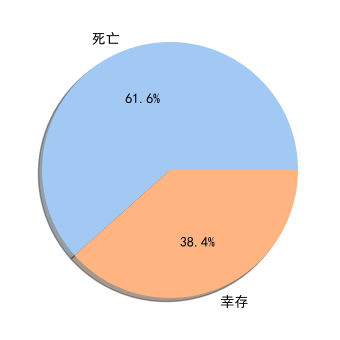

In [428]:
#根据样本变量来绘制幸存者比例饼图
sc=ctr["Survived"].value_counts()
survived_label = sc.index
plt.pie(sc,labels=["死亡","幸存"],autopct="%1.1f%%",shadow=True)
plt.show()
#这里第一次运行出现过一次问题，文字出现了“豆腐块”，后来发现是因为matplotlib中默认的字体没有中文因此渲染成了豆腐块；后来在引入matplotlib库后，设置了中文字体SimHei，问题就解决了。
#根据绘制结果可知，死亡人数较多，为幸存数量的两倍左右。

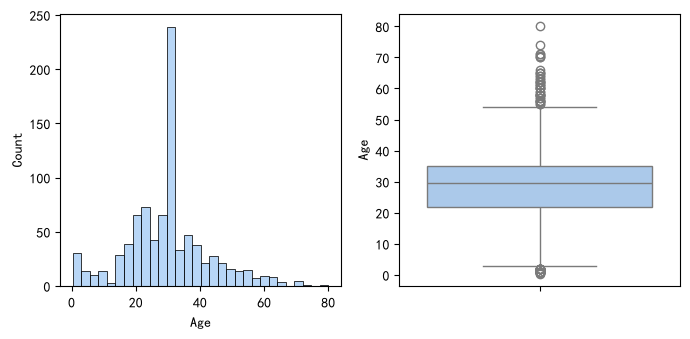

In [429]:
#接下来探索乘客年龄分布
figure,axes=plt.subplots(1,2)
sns.histplot(ctr, x='Age', ax=axes[0])
sns.boxplot(ctr, y='Age', ax=axes[1])
plt.show()
#从下面的输出结果来看，年龄分布大致呈现正态分布，年龄主要集中在20-40岁之间。

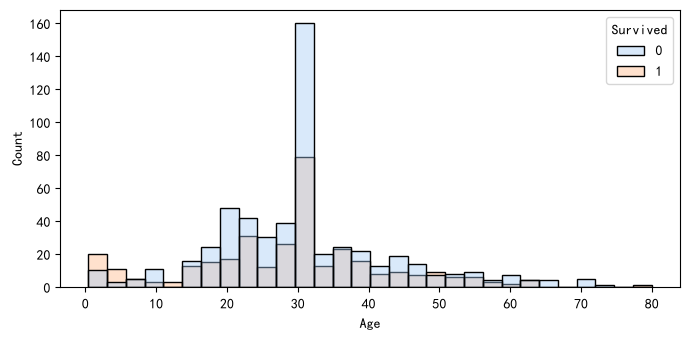

In [430]:
#接下来探索年龄和是否幸存之间的关系
sns.histplot(ctr, x='Age', hue='Survived', alpha=0.4)
plt.show()
#从下面的输出结果来看，只有婴儿和儿童的幸存率较高，其他年龄段的幸存率较低，尤其是中年人群的幸存率最低。其死亡人数远高于生存人数。

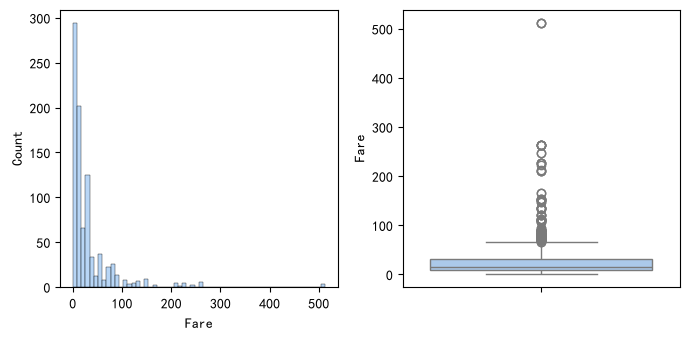

In [431]:
#接下来探索票价分布
figure, axes = plt.subplots(1, 2, figsize=[7, 3.5])
sns.histplot(ctr, x='Fare', ax=axes[0])
sns.boxplot(ctr, y='Fare', ax=axes[1])
plt.show()
#从下面的输出结果来看，票价分布呈现右偏态分布，票价主要集中在0-100元之间，存在一些极端值使得整体票价得到拉升。

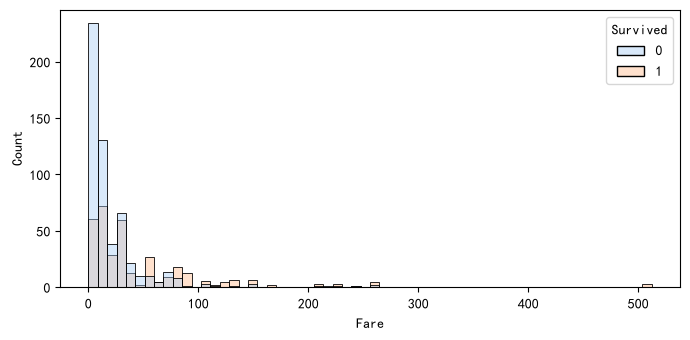

In [432]:
#接下来探索票价和是否幸存之间的关系
sns.histplot(ctr, x='Fare', hue='Survived', alpha=0.4)
plt.show()
#从探索结果可知，票价在0-100元之间的乘客死亡人数远高于幸存人数，而票价在100元以上的乘客幸存人数远高于死亡人数。

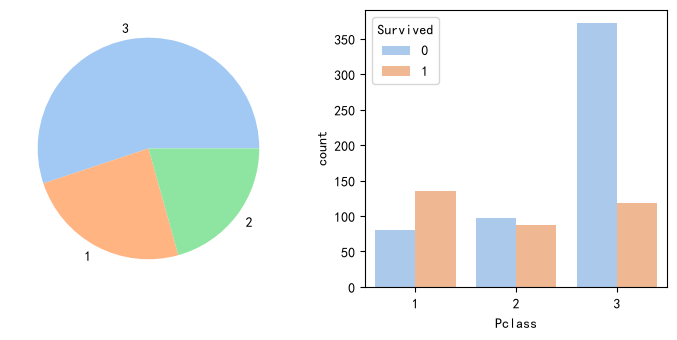

In [433]:
#接下来探索船舱等级和是否幸存之间的关系
figure, axes = plt.subplots(1, 2)
pc = ctr['Pclass'].value_counts()
pcl = pc.index
#index用于提取出索引值，作为饼图的标签
axes[0].pie(pc, labels=pcl)
sns.countplot(ctr, x='Pclass', hue='Survived', ax=axes[1])
plt.show()
#从探索结果可知，船舱等级为1的乘客幸存人数远高于死亡人数，而船舱等级为2和3的乘客死亡人数远高于幸存人数。

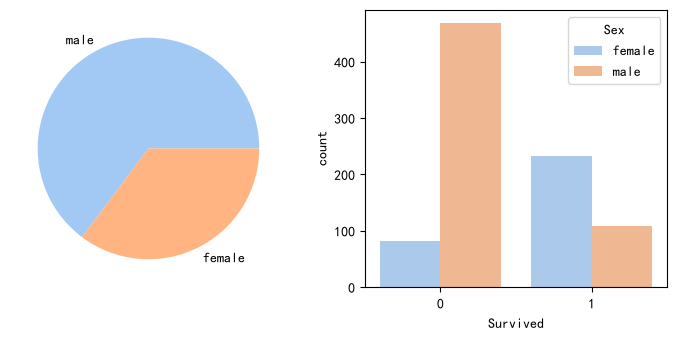

In [434]:
#性别与是否生存之间的关系
figure, axes = plt.subplots(1, 2)
sc = ctr['Sex'].value_counts()
sll = sc.index
axes[0].pie(sc, labels=sll)
sns.countplot(ctr, x='Survived', hue='Sex', ax=axes[1])
plt.show()
#从探索结果可知，女性乘客的幸存人数远高于死亡人数，而男性乘客的死亡人数远高于幸存人数。

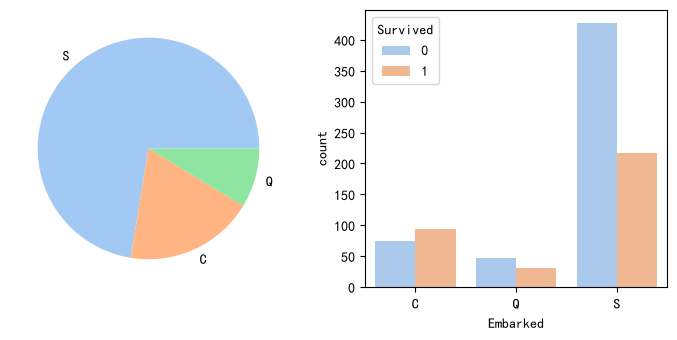

In [435]:
#登船港口与是否幸存的关系
figure, axes = plt.subplots(1, 2)
ec = ctr['Embarked'].value_counts()
el = ec.index
axes[0].pie(ec , labels=el)
sns.countplot(ctr, x='Embarked', hue='Survived', ax=axes[1])
plt.show()
#从输出结果可知，登船港口为C的乘客幸存人数高于死亡人数，而登船港口为Q和S的乘客死亡人数高于幸存人数。

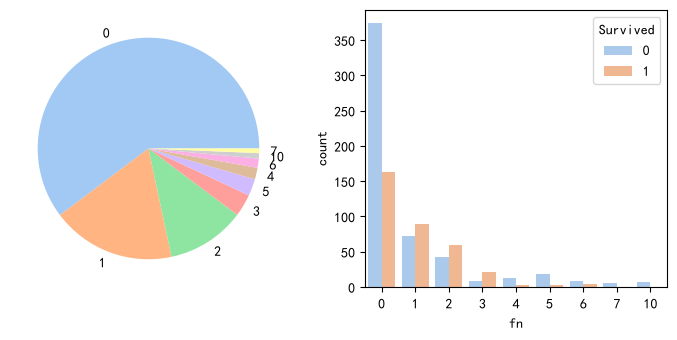

In [436]:
#家庭成员数与是否幸存的关系
figure,axes=plt.subplots(1,2)
fc=ctr["fn"].value_counts()
fl=fc.index
axes[0].pie(fc,labels=fl)
sns.countplot(ctr,x="fn",hue="Survived",ax=axes[1])
plt.show()
#从是否幸存与乘客家庭成员之间的柱状图来看，独身的乘客中遇难的多于幸存的。从有携带家庭成员的乘客来看，家庭成员在1～3位之间的幸存人数超过遇难人数，但同乘家庭成员超过3位后，遇难的更多。

In [437]:
ctr.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    str     
 1   Survived     891 non-null    category
 2   Pclass       891 non-null    category
 3   Name         891 non-null    str     
 4   Sex          891 non-null    category
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    str     
 9   Fare         891 non-null    float64 
 10  Cabin        204 non-null    str     
 11  Embarked     889 non-null    category
 12  fn           891 non-null    int64   
dtypes: category(4), float64(2), int64(3), str(4)
memory usage: 66.8 KB


## 分析数据

在分析步骤中，将利用清理过的数据进行逻辑回归分析，从而是得到一个可以根据泰坦尼克号乘客各个属性，对沉船事件后幸存情况进行预测的数学模型。  
首先引入做逻辑回归所需的模块。

In [438]:
import statsmodels.api as sm  

##### 为了基于已经处理好的数据，可将其重新赋值为一个新的DataFrame，从而使得接下来的所有分析步骤和处理发生在新的DF上

In [439]:
lrctr=ctr.copy()
lrctr.head(10)
#从数据输出结果来看，数据中乘客编号（passenger）、名字（name）、船舱号（cabin）、登船港口（embarked）、票号（ticket）
#这些数据对于逻辑回归分析没有关键影响作用，因此不将其纳入逻辑分析中。

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,fn
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,NaN,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,NaN,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,C123,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,NaN,S,0
5,6,0,3,"Moran, Mr. James",male,29.699118,0,0,330877,8.4583,NaN,Q,0
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.000000,0,0,17463,51.8625,E46,S,0
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,349909,21.0750,NaN,S,4
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.000000,0,2,347742,11.1333,NaN,S,2
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.000000,1,0,237736,30.0708,NaN,C,1


In [440]:
lrcrt=lrctr.drop(['PassengerId','Name','Cabin','Embarked','Ticket'],axis=1)
lrcrt.head(10)
#接下来应该将分类变量转换为虚拟变量。
#根据对剩余数据的观察发现：survived本身就是用0和1来表示的因此不需要更改、
#而pclass、sex这两列也是分类变量，因此需要将其转换为虚拟变量。

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,fn
0,0,3,male,22.000000,1,0,7.2500,1
1,1,1,female,38.000000,1,0,71.2833,1
2,1,3,female,26.000000,0,0,7.9250,0
3,1,1,female,35.000000,1,0,53.1000,1
4,0,3,male,35.000000,0,0,8.0500,0
5,0,3,male,29.699118,0,0,8.4583,0
6,0,1,male,54.000000,0,0,51.8625,0
7,0,3,male,2.000000,3,1,21.0750,4
8,1,3,female,27.000000,0,2,11.1333,2
9,1,2,female,14.000000,1,0,30.0708,1


In [441]:
lrcrt=pd.get_dummies(lrcrt, drop_first=True,columns=['Pclass', 'Sex'],dtype=int)
lrcrt.head(10)
#下一步要划分自变量和因变量,因变量是survived，自变量是除了survived列之外的所有其他列

,Survived,Age,SibSp,Parch,Fare,fn,Pclass_2,Pclass_3,Sex_male
0,0,22.000000,1,0,7.2500,1,0,1,1
1,1,38.000000,1,0,71.2833,1,0,0,0
2,1,26.000000,0,0,7.9250,0,0,1,0
3,1,35.000000,1,0,53.1000,1,0,0,0
4,0,35.000000,0,0,8.0500,0,0,1,1
5,0,29.699118,0,0,8.4583,0,0,1,1
6,0,54.000000,0,0,51.8625,0,0,0,1
7,0,2.000000,3,1,21.0750,4,0,1,1
8,1,27.000000,0,2,11.1333,2,0,1,0
9,1,14.000000,1,0,30.0708,1,1,0,0


In [442]:
y=lrcrt["Survived"]
x=lrcrt.drop("Survived",axis=1)
x.corr()
#划分之后，还需要进行相关性进行检查，从而避免多重共线性问题的出现，避免影响逻辑回归分析的结果。

,Age,SibSp,Parch,Fare,fn,Pclass_2,Pclass_3,Sex_male
Age,1.000000,-0.232625,-0.179191,0.091566,-0.248512,0.006589,-0.281004,0.084153
SibSp,-0.232625,1.000000,0.414838,0.159651,0.890712,-0.055932,0.092548,-0.114631
Parch,-0.179191,0.414838,1.000000,0.216225,0.783111,-0.000734,0.015790,-0.245489
Fare,0.091566,0.159651,0.216225,1.000000,0.217138,-0.118557,-0.413333,-0.182333
fn,-0.248512,0.890712,0.783111,0.217138,1.000000,-0.038594,0.071142,-0.200988
Pclass_2,0.006589,-0.055932,-0.000734,-0.118557,-0.038594,1.000000,-0.565210,-0.064746
Pclass_3,-0.281004,0.092548,0.015790,-0.413333,0.071142,-0.565210,1.000000,0.137143
Sex_male,0.084153,-0.114631,-0.245489,-0.182333,-0.200988,-0.064746,0.137143,1.000000


In [443]:
x.corr().abs()>0.8
#从输出结果可知，fn是SibSp和Parch的和，因此fn与SibSp、Parch之间存在高度相关性，可能会影响逻辑回归分析的结果;
#因此需要删除其中一列，现在删除SibSp列;然后，Parch列也和fn存在高度相关性，也需要删除。

,Age,SibSp,Parch,Fare,fn,Pclass_2,Pclass_3,Sex_male
Age,True,False,False,False,False,False,False,False
SibSp,False,True,False,False,True,False,False,False
Parch,False,False,True,False,False,False,False,False
Fare,False,False,False,True,False,False,False,False
fn,False,True,False,False,True,False,False,False
Pclass_2,False,False,False,False,False,True,False,False
Pclass_3,False,False,False,False,False,False,True,False
Sex_male,False,False,False,False,False,False,False,True


In [444]:
x=x.drop("SibSp",axis=1)
x=x.drop("Parch",axis=1)
x.head(10)
#现在完成了移除工作，接下来可以为线性方程添加截距

,Age,Fare,fn,Pclass_2,Pclass_3,Sex_male
0,22.000000,7.2500,1,0,1,1
1,38.000000,71.2833,1,0,0,0
2,26.000000,7.9250,0,0,1,0
3,35.000000,53.1000,1,0,0,0
4,35.000000,8.0500,0,0,1,1
5,29.699118,8.4583,0,0,1,1
6,54.000000,51.8625,0,0,0,1
7,2.000000,21.0750,4,0,1,1
8,27.000000,11.1333,2,0,1,0
9,14.000000,30.0708,1,1,0,0


In [445]:
x=sm.add_constant(x)
#接下来就可以调用Logit函数来利用最大似然优化来得到逻辑回归模型的参数值，并输出总结信息，Logit函数的第一个参数是因变量，第二个参数是自变量。
lm=sm.Logit(y,x)

In [446]:
md=lm.fit()

Optimization terminated successfully.
         Current function value: 0.443547
         Iterations 6


In [447]:
md.summary()
#从下面的输出结果来看，模型认为：除了Fare即船票以外的所有自变量的p值都小于0.05，即船票对于因变量没有显著的预测作用，可以将其删除。

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               Survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      884
Method:                           MLE   Df Model:                            6
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                  0.3339
Time:                        20:44:42   Log-Likelihood:                -395.20
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 1.786e-82
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.8097      0.445      8.568      0.000       2.938       4.681
Age           -0.0388      0.008     -4.963      0.000      -0.054      -0.023
Fare           0.0032      0.002      1.311      0.190      -0.002       0.008
fn            -0.2430      0.068     -3.594      0.000      -0.376      -0.110
Pclass_2      -1.0003      0.293     -3.416      0.001      -1.574      -0.426
Pclass_3      -2.1324      0.289     -7.373      0.000      -2.699      -1.566
Sex_male      -2.7759      0.199    -13.980      0.000      -3.165      -2.387
==============================================================================
"""

In [448]:
x=x.drop("Fare",axis=1)
ml=sm.Logit(y,x).fit()
ml.summary()
#删除完成后观察coef可以发现，除了常数以外，所有自变量的系数都为负数：
#说明这些自变量与因变量之间存在负相关关系，即这些自变量的值越大，乘客幸存的可能性就越小。
#这些变量包括：年龄、同乘成员数、不在一等舱、性别为男性。

Optimization terminated successfully.
         Current function value: 0.444623
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               Survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      885
Method:                           MLE   Df Model:                            5
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                  0.3323
Time:                        20:44:42   Log-Likelihood:                -396.16
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 4.927e-83
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0620      0.404     10.049      0.000       3.270       4.854
Age           -0.0395      0.008     -5.065      0.000      -0.055      -0.024
fn            -0.2186      0.065     -3.383      0.001      -0.345      -0.092
Pclass_2      -1.1798      0.261     -4.518      0.000      -1.692      -0.668
Pclass_3      -2.3458      0.242     -9.676      0.000      -2.821      -1.871
Sex_male      -2.7854      0.198    -14.069      0.000      -3.173      -2.397
==============================================================================
"""

In [449]:
#要理解各个自变量系数的实际含义、需要计算自然常数的次方。
np.exp(-0.0395) # Age
#输出结果的含义为，乘客年龄每增加一岁，生还的概率就要乘以0.9613，即生还的概率就会降低3.87%。

np.float64(0.9612699539905982)

In [450]:
np.exp(-0.3829) # fn
#输出结果的含义为，乘客同乘家庭成员数每增加一位，生还的概率就要乘以0.6820，即生还的概率就会降低31.80%。

np.float64(0.6818810839850973)

In [451]:
np.exp(-1.1798) #Pclass_2
#输出结果的含义为，乘客在二等舱的生还概率就要乘以0.3074，即生还的概率就会降低69.26%。

np.float64(0.30734020049483596)

In [452]:
np.exp(-2.3458) #Pclass_3
#输出结果的含义为，乘客在三等舱的生还概率就要乘以0.0960，即生还的概率就会降低90.40%。

np.float64(0.09577055503172162)

In [453]:
np.exp(-2.7854) #Sex_male
#输出结果的含义为，乘客为男性的生还概率就要乘以0.0618，即生还的概率就会降低93.82%。

np.float64(0.061704402333015156)

#### 根据模型的参数值，可以发现：  
根据模型参数值总结：
- 年龄小的乘客幸存概率更高；
- 女性乘客的生还率比男性乘客的幸存概率更高；
- 来自的船舱等级高的乘客幸存概率更高；
- 同乘家庭成员少的乘客幸存概率更高。  

前两条背后的原因可能与泰坦尼克号沉船后逃生时：“让孩子和女性先走”的原则。  
第三条说明可能当时舱位更尊贵的乘客拥有优先逃生的机会。  
第四条可能是因为拥有较大数量家庭成员的乘客在灾难发生时会急于解救其他家庭成员而非选择逃生，最后也失去了自己逃生的机会。

In [454]:
tt=pd.read_csv(r"C:\Users\30338\Desktop\数据处理学习\5数据分析\titanic_test.csv")
tt.head(10)
#由于逻辑回归分析中不允许存在缺失值，因此还是需要对数据进行检查

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
5,897,3,"Svensson, Mr. Johan Cervin",male,14.0,0,0,7538,9.2250,NaN,S
6,898,3,"Connolly, Miss. Kate",female,30.0,0,0,330972,7.6292,NaN,Q
7,899,2,"Caldwell, Mr. Albert Francis",male,26.0,1,1,248738,29.0000,NaN,S
8,900,3,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",female,18.0,0,0,2657,7.2292,NaN,C
9,901,3,"Davies, Mr. John Samuel",male,21.0,2,0,A/4 48871,24.1500,NaN,S


In [455]:
tt.info()
#从输出结果来看，Age、Fare、Cabin这三列存在缺失值，因此需要对其进行处理。

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


In [456]:
#由于模型没有用到Fare和Cabin这两列，因此不需要对其进行处理，而Age列在模型中有使用，因此需要对其进行处理。
#在对Age列进行处理时，发现Age列的缺失值数量为86个，占总数的19.87%，因此需要对其进行处理。
#根据前面对Age进行的处理可以取平均值
tt["Age"]=tt["Age"].fillna(tt["Age"].mean())
tt["Age"].isna().sum()
#经过处理后，Age列的缺失值已经被填充为Age列的均值，查看Age列是否还存在缺失值，发现已经不存在缺失值了。

np.int64(0)

##### 下一步要给模型中的分类变量引入虚拟变量，但在引入前需要先把分类变量的类型转换为Category，并且通过`categories`参数，让程序知道所有可能的分类值。这样做的原因是，预测数据包含的分类可能不全。需要确保引入虚拟变量的时候，不会漏掉某个或某些分类。

In [457]:
tt["Pclass"]=pd.Categorical(tt["Pclass"],categories=["1","2","3"])
tt["Sex"]=pd.Categorical(tt["Sex"],categories=["female","male"])
tt["Embarked"]=pd.Categorical(tt["Embarked"],categories=["C","Q","S"])
#接下来需要对分类变量引入虚拟变量

C:\Users\30338\AppData\Local\Temp\ipykernel_23736\452515237.py:1: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  tt["Pclass"]=pd.Categorical(tt["Pclass"],categories=["1","2","3"])


In [ ]:
tt=pd.get_dummies(tt,drop_first=True,columns=['Pclass', 'Sex'],dtype=int)
tt.head(10)
#然后通过params参数，查看模型需要输入的变量

,PassengerId,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Pclass_2,Pclass_3,Sex_male
0,892,"Kelly, Mr. James",34.5,0,0,330911,7.8292,NaN,Q,0,0,1
1,893,"Wilkes, Mrs. James (Ellen Needs)",47.0,1,0,363272,7.0000,NaN,S,0,0,0
2,894,"Myles, Mr. Thomas Francis",62.0,0,0,240276,9.6875,NaN,Q,0,0,1
3,895,"Wirz, Mr. Albert",27.0,0,0,315154,8.6625,NaN,S,0,0,1
4,896,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",22.0,1,1,3101298,12.2875,NaN,S,0,0,0
5,897,"Svensson, Mr. Johan Cervin",14.0,0,0,7538,9.2250,NaN,S,0,0,1
6,898,"Connolly, Miss. Kate",30.0,0,0,330972,7.6292,NaN,Q,0,0,0
7,899,"Caldwell, Mr. Albert Francis",26.0,1,1,248738,29.0000,NaN,S,0,0,1
8,900,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",18.0,0,0,2657,7.2292,NaN,C,0,0,0
9,901,"Davies, Mr. John Samuel",21.0,2,0,A/4 48871,24.1500,NaN,S,0,0,1


In [464]:
ml.params
#根据模型的参数，模型需要输入的变量有fn，因此需要在tt中添加fn列，fn列的值为SibSp和Parch的和。

const       4.061982
Age        -0.039495
fn         -0.218627
Pclass_2   -1.179763
Pclass_3   -2.345823
Sex_male   -2.785398
dtype: float64

In [465]:
tt["fn"]=tt["SibSp"]+tt["Parch"]
tt.head(10)
#模型变量需要和训练时的数据变量保持一致

,PassengerId,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Pclass_2,Pclass_3,Sex_male,fn
0,892,"Kelly, Mr. James",34.5,0,0,330911,7.8292,NaN,Q,0,0,1,0
1,893,"Wilkes, Mrs. James (Ellen Needs)",47.0,1,0,363272,7.0000,NaN,S,0,0,0,1
2,894,"Myles, Mr. Thomas Francis",62.0,0,0,240276,9.6875,NaN,Q,0,0,1,0
3,895,"Wirz, Mr. Albert",27.0,0,0,315154,8.6625,NaN,S,0,0,1,0
4,896,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",22.0,1,1,3101298,12.2875,NaN,S,0,0,0,2
5,897,"Svensson, Mr. Johan Cervin",14.0,0,0,7538,9.2250,NaN,S,0,0,1,0
6,898,"Connolly, Miss. Kate",30.0,0,0,330972,7.6292,NaN,Q,0,0,0,0
7,899,"Caldwell, Mr. Albert Francis",26.0,1,1,248738,29.0000,NaN,S,0,0,1,2
8,900,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",18.0,0,0,2657,7.2292,NaN,C,0,0,0,0
9,901,"Davies, Mr. John Samuel",21.0,2,0,A/4 48871,24.1500,NaN,S,0,0,1,2


In [ ]:
x
#从观察可知，需要传入的数据包括const、Age、fn、Pclass、set

,const,Age,fn,Pclass_2,Pclass_3,Sex_male
0,1.0,22.000000,1,0,1,1
1,1.0,38.000000,1,0,0,0
2,1.0,26.000000,0,0,1,0
3,1.0,35.000000,1,0,0,0
4,1.0,35.000000,0,0,1,1
...,...,...,...,...,...,...
886,1.0,27.000000,0,1,0,1
887,1.0,19.000000,0,0,0,0
888,1.0,29.699118,3,0,1,0
889,1.0,26.000000,0,0,0,1


In [ ]:
xt=tt[["Age","fn","Pclass_2","Pclass_3","Sex_male"]]
xt=sm.add_constant(xt)
#到此为止，自变量准备完毕，接下来就要调用逻辑回归模型的predict方法来进行预测。

In [473]:
pv=ml.predict(xt)
pv
#输出结果就是对测试数据集中的400多位乘客的生还概率，接下来将生存概率大于0.5的乘客判断输出

0      0.478514
1      0.879434
2      0.236473
3      0.552361
4      0.940242
         ...   
413    0.520230
414    0.925647
415    0.439306
416    0.520230
417    0.411858
Length: 418, dtype: float64

In [ ]:
pv>0.5

0      False
1       True
2      False
3       True
4       True
       ...  
413     True
414     True
415    False
416     True
417    False
Length: 418, dtype: bool